PASUL 1: Matricea X

In [5]:
!pip install osmnx folium mapclassify -q

import ee
import osmnx as ox
import time
import geopandas as gpd
import pandas as pd
import warnings
from shapely.geometry import box
from IPython.display import display

warnings.filterwarnings('ignore')

# Initializare si Autentificare Google Earth Engine
print("[LOG] Initializare GEE...")
ee.Authenticate() # Decomenteaza la prima rulare pentru autentificare
ee.Initialize(project='mede-511511')
print("[LOG] GEE Initializat.\n")

# ==========================================
# 0. GENERARE GRID (500m) - Unitatea de analiza
# ==========================================
print("[LOG] 0. Se genereaza gridul de 500m pentru Bucuresti...")
# Definim bounding box-ul pentru Bucuresti [Vest, Sud, Est, Nord]
bbox = [25.99, 44.38, 26.18, 44.50]
roi = ee.Geometry.Rectangle(bbox)
# Proiectia folosita va fi EPSG:32635 (WGS 84 / UTM zone 35N)
projection = ee.Projection('EPSG:32635')

# Cream grid-ul propriu-zis cu rezolutia de 500m
grid_500m = ee.Geometry.Rectangle(bbox).coveringGrid(projection, 500)
aria_celula_m2 = 500 * 500

print("[LOG] 0. Grid generat pe serverul GEE.\n")

# ==========================================
# 1. SURSA 1: LANDSAT 9 (Termic - LST)
# ==========================================
print("[LOG] 1. Extragere si agregare Landsat 9 LST...")
# Functie pentru conversia in grade Celsius
def extract_lst(image):
    thermal = image.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15)
    return image.addBands(thermal.rename('LST_Celsius'))

# Filtram colectia: perioada verii 2026, acoperire nori < 10% si facem media
l9_mean = (ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
           .filterBounds(roi)
           .filterDate('2026-06-01', '2026-08-31')
           .filter(ee.Filter.lt('CLOUD_COVER', 10))
           .map(extract_lst)
           .select('LST_Celsius')
           .mean())

# Aliniere spatiala: aplicam reducer-ul (media pixelilor de 30m) pe gridul de 500m
grid_gee = l9_mean.reduceRegions(collection=grid_500m, reducer=ee.Reducer.mean(), scale=30)\
                  .map(lambda f: f.set('LST_Mediu_C', f.get('mean')))
print("[LOG] 1. Landsat 9 procesat (Target extras).\n")

# ==========================================
# 2. SURSA 2: SENTINEL-2 (Optic - NDVI)
# ==========================================
print("[LOG] 2. Extragere si agregare Sentinel-2 NDVI...")
# Functie pentru calculul NDVI
def add_ndvi(image):
    return image.addBands(image.normalizedDifference(['B8', 'B4']).rename('NDVI'))

# Filtram colectia Sentinel-2, aplicam NDVI si facem media pe vara
s2_mean = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
           .filterBounds(roi)
           .filterDate('2026-06-01', '2026-08-31')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
           .map(add_ndvi)
           .select('NDVI')
           .mean())

# Aliniere spatiala: media pixelilor de 10m in fiecare celula de 500m
grid_gee = s2_mean.reduceRegions(collection=grid_gee, reducer=ee.Reducer.mean(), scale=10)\
                  .map(lambda f: f.set('NDVI_Mediu', f.get('mean')))
print("[LOG] 2. Sentinel-2 procesat.\n")

# ==========================================
# 3. SURSA 3: GHSL (Inaltime Cladiri)
# ==========================================
print("[LOG] 3. Extragere GHSL (Inaltime cladiri)...")
# Folosim layer-ul de inaltimi (metri) din GHSL
ghsl_height = ee.Image("JRC/GHSL/P2023A/GHS_BUILT_H/2018").select('built_height')

# Aliniere spatiala: media pixelilor de 100m in fiecare celula de 500m
grid_gee = ghsl_height.reduceRegions(collection=grid_gee, reducer=ee.Reducer.mean(), scale=100)\
                      .map(lambda f: f.set('Inaltime_GHSL_m', f.get('mean')))
print("[LOG] 3. GHSL procesat.\n")

# ==========================================
# 4. EXTRAGERE DATE SPRE GEOPANDAS
# ==========================================
print("[LOG] 4. Se descarca datele din GEE in format GeoDataFrame...")
# Reproiectam catre WGS84 pentru extragere rapida, vom converti apoi in UTM
grid_gee = grid_gee.map(lambda f: ee.Feature(f).transform('EPSG:4326', 0.001))
features = grid_gee.getInfo()['features']

grid_gdf = gpd.GeoDataFrame.from_features(features)
# Convertim la sistem de coordonate proiectat pentru calcule precise de arie si lungime
grid_gdf = grid_gdf.set_crs("EPSG:4326", allow_override=True).to_crs("EPSG:32635")
grid_gdf['ID_Celula'] = range(len(grid_gdf))
grid_gdf['geometry'] = grid_gdf.geometry.buffer(0)

# Curatare coloane inutile generate de reduceri
for col in ['mean']:
    if col in grid_gdf.columns:
        grid_gdf = grid_gdf.drop(columns=[col])
print(f"[LOG] 4. Baza gridului GEE este gata: {len(grid_gdf)} randuri.\n")

# ==========================================
# 5. SURSA 4: OSMNX (Forma Urbana vectoriala)
# ==========================================
print("[LOG] 5. Incepe interogarea vectoriala prin OSMnx...")

# Resetam setarile ramase in memorie pentru a evita conflictul de 'timeout'
ox.settings.requests_kwargs = {}
ox.settings.timeout = 600

# Functie robusta pentru descarcare cu reincercari (Exponential Backoff)
def fetch_osm_with_retry(polygon, tags, max_retries=5):
    for attempt in range(max_retries):
        try:
            print(f"    -> Incercare {attempt + 1}/{max_retries}...")
            gdf = ox.features_from_polygon(polygon=polygon, tags=tags)
            return gdf
        except Exception as e:
            print(f"    -> Eroare: {e}")
            wait_time = 10 * (2 ** attempt)
            print(f"    -> Asteptam {wait_time} secunde si reincercam...")
            time.sleep(wait_time)
    raise Exception("Overpass API nu raspunde. Incearca mai tarziu.")

roi_poly = box(bbox[0], bbox[1], bbox[2], bbox[3])

# 5.1 Amprenta Cladirilor
print("[LOG] 5.1. Descarcare si intersectie cladiri OSM...")
osm_buildings = fetch_osm_with_retry(roi_poly, tags={'building': True}).to_crs("EPSG:32635")
osm_buildings = osm_buildings[osm_buildings.geom_type.isin(['Polygon', 'MultiPolygon'])].reset_index()
osm_buildings['geometry'] = osm_buildings.geometry.buffer(0)
intersect_bld = gpd.overlay(grid_gdf[['ID_Celula', 'geometry']], osm_buildings[['geometry']], how='intersection')
intersect_bld['aria'] = intersect_bld.geometry.area
aria_bld = intersect_bld.groupby('ID_Celula')['aria'].sum().reset_index(name='Aria_Cladiri_m2')

# 5.2 Parcuri
print("[LOG] 5.2. Descarcare si intersectie parcuri OSM...")
osm_parks = fetch_osm_with_retry(roi_poly, tags={'leisure': 'park', 'landuse': ['grass', 'forest']}).to_crs("EPSG:32635")
osm_parks = osm_parks[osm_parks.geom_type.isin(['Polygon', 'MultiPolygon'])].reset_index()
osm_parks['geometry'] = osm_parks.geometry.buffer(0)
intersect_prk = gpd.overlay(grid_gdf[['ID_Celula', 'geometry']], osm_parks[['geometry']], how='intersection')
intersect_prk['aria'] = intersect_prk.geometry.area
aria_prk = intersect_prk.groupby('ID_Celula')['aria'].sum().reset_index(name='Aria_Parcuri_m2')

# 5.3 Drumuri (Reteaua principala si rezidentiala)
print("[LOG] 5.3. Descarcare si intersectie drumuri OSM (doar reteaua auto/rezidentiala)...")
tags_drumuri = {
    'highway': ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'unclassified', 'residential']
}
osm_roads = fetch_osm_with_retry(roi_poly, tags=tags_drumuri).to_crs("EPSG:32635")
osm_roads = osm_roads[osm_roads.geom_type.isin(['LineString', 'MultiLineString'])].reset_index()
intersect_rds = gpd.overlay(grid_gdf[['ID_Celula', 'geometry']], osm_roads[['geometry']], how='intersection', keep_geom_type=False)
intersect_rds['lungime'] = intersect_rds.geometry.length
lungime_rds = intersect_rds.groupby('ID_Celula')['lungime'].sum().reset_index(name='Lungime_Drumuri_m')

# 5.4 Integrare rezultate
print("[LOG] 5.4. Imbinare rezultate OSM cu gridul principal...")
grid_gdf = grid_gdf.merge(aria_bld, on='ID_Celula', how='left').fillna({'Aria_Cladiri_m2': 0})
grid_gdf = grid_gdf.merge(aria_prk, on='ID_Celula', how='left').fillna({'Aria_Parcuri_m2': 0})
grid_gdf = grid_gdf.merge(lungime_rds, on='ID_Celula', how='left').fillna({'Lungime_Drumuri_m': 0})

grid_gdf['Fractie_Cladiri_OSM'] = grid_gdf['Aria_Cladiri_m2'] / aria_celula_m2
grid_gdf['Fractie_Parcuri_OSM'] = grid_gdf['Aria_Parcuri_m2'] / aria_celula_m2
grid_gdf['Densitate_Drumuri'] = grid_gdf['Lungime_Drumuri_m'] / aria_celula_m2

# ==========================================
# 6. TRATARE GOLURI, MATRICE X SI AFISARE HARTA
# ==========================================
print("[LOG] 6. Tratare goluri si finalizare Matrice X...")

# Pastram si coloana 'geometry' in GeoDataFrame pentru a putea afisa gridul pe harta
coloane_cu_geometrie = [
    'ID_Celula', 'LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m',
    'Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri', 'geometry'
]

# Eliminarea celulelor fara date valide de temperatura sau NDVI
matrice_X_gdf = grid_gdf.dropna(subset=['LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m'])[coloane_cu_geometrie].copy()
matrice_X_gdf.reset_index(drop=True, inplace=True)

# Salvam tabelul curat (fara geometrie) in CSV pentru pasii urmatori
matrice_X_gdf.drop(columns=['geometry']).to_csv('matrice_X_salvata.csv', index=False)

print("\n--- MATRICEA X A FOST GENERATA ---")
# Afisam dimensiunea si primele 5 randuri excluzand ID_Celula si geometry
print(f"Dimensiune finala (n esantioane x d trasaturi): {matrice_X_gdf.shape[0]} x {matrice_X_gdf.shape[1]-2}")
print("\nPrimele 5 randuri din Matricea X:")
print(matrice_X_gdf.drop(columns=['geometry']).head())

# ==========================================
# 7. VIZUALIZARE HARTA INTERACTIVA (CORECTATA)
# ==========================================
from IPython.display import display
import folium

print("[LOG] Se calculează coordonatele pentru linkurile de Google Maps...")
# Extragem coordonatele centrului fiecărei celule, transformate în sistem GPS (EPSG:4326)
centru_gps = matrice_X_gdf.to_crs("EPSG:4326").geometry.centroid
matrice_X_gdf['Google_Maps'] = [
    f'<a href="https://www.google.com/maps?q={lat},{lon}" target="_blank">Deschide în Google Maps</a>'
    for lat, lon in zip(centru_gps.y, centru_gps.x)
]

print("[LOG] Se generează harta interactivă cu fundal Esri și link-uri...")

# Construire hartă interactivă folosind fundal public Esri cu 20 de trepte de culori
harta = matrice_X_gdf.explore(
    column="LST_Mediu_C",
    cmap="RdYlBu_r",
    scheme="Quantiles",
    k=20,                       # 20 de trepte de culori pentru o tranziție fină
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ",
    tooltip=[
        "ID_Celula", "LST_Mediu_C", "NDVI_Mediu",
        "Inaltime_GHSL_m", "Fractie_Cladiri_OSM",
        "Fractie_Parcuri_OSM", "Densitate_Drumuri"
    ],
    popup=[
        "ID_Celula", "LST_Mediu_C", "Google_Maps"
    ],
    style_kwds={"weight": 1, "color": "black", "fillOpacity": 0.75},
    name="Grid București (500m)"
)

# Salvare și afișare directă în notebook
harta.save("harta_selectie_grid_500m.html")
display(harta)
print("[LOG] Harta a fost generată, salvată ca HTML și afișată cu succes!")

[LOG] Initializare GEE...
[LOG] GEE Initializat.

[LOG] 0. Se genereaza gridul de 500m pentru Bucuresti...
[LOG] 0. Grid generat pe serverul GEE.

[LOG] 1. Extragere si agregare Landsat 9 LST...
[LOG] 1. Landsat 9 procesat (Target extras).

[LOG] 2. Extragere si agregare Sentinel-2 NDVI...
[LOG] 2. Sentinel-2 procesat.

[LOG] 3. Extragere GHSL (Inaltime cladiri)...
[LOG] 3. GHSL procesat.

[LOG] 4. Se descarca datele din GEE in format GeoDataFrame...
[LOG] 4. Baza gridului GEE este gata: 856 randuri.

[LOG] 5. Incepe interogarea vectoriala prin OSMnx...
[LOG] 5.1. Descarcare si intersectie cladiri OSM...
    -> Incercare 1/5...
[LOG] 5.2. Descarcare si intersectie parcuri OSM...
    -> Incercare 1/5...
[LOG] 5.3. Descarcare si intersectie drumuri OSM (doar reteaua auto/rezidentiala)...
    -> Incercare 1/5...
[LOG] 5.4. Imbinare rezultate OSM cu gridul principal...
[LOG] 6. Tratare goluri si finalizare Matrice X...

--- MATRICEA X A FOST GENERATA ---
Dimensiune finala (n esantioane x d

[LOG] Harta a fost generată, salvată ca HTML și afișată cu succes!


PASUL 2: Analiza statistică descriptivă.

[LOG] Incepe Pasul 2: Analiza statistica descriptiva...
[LOG] 2.1 Generare histograme (analiza univariata)...


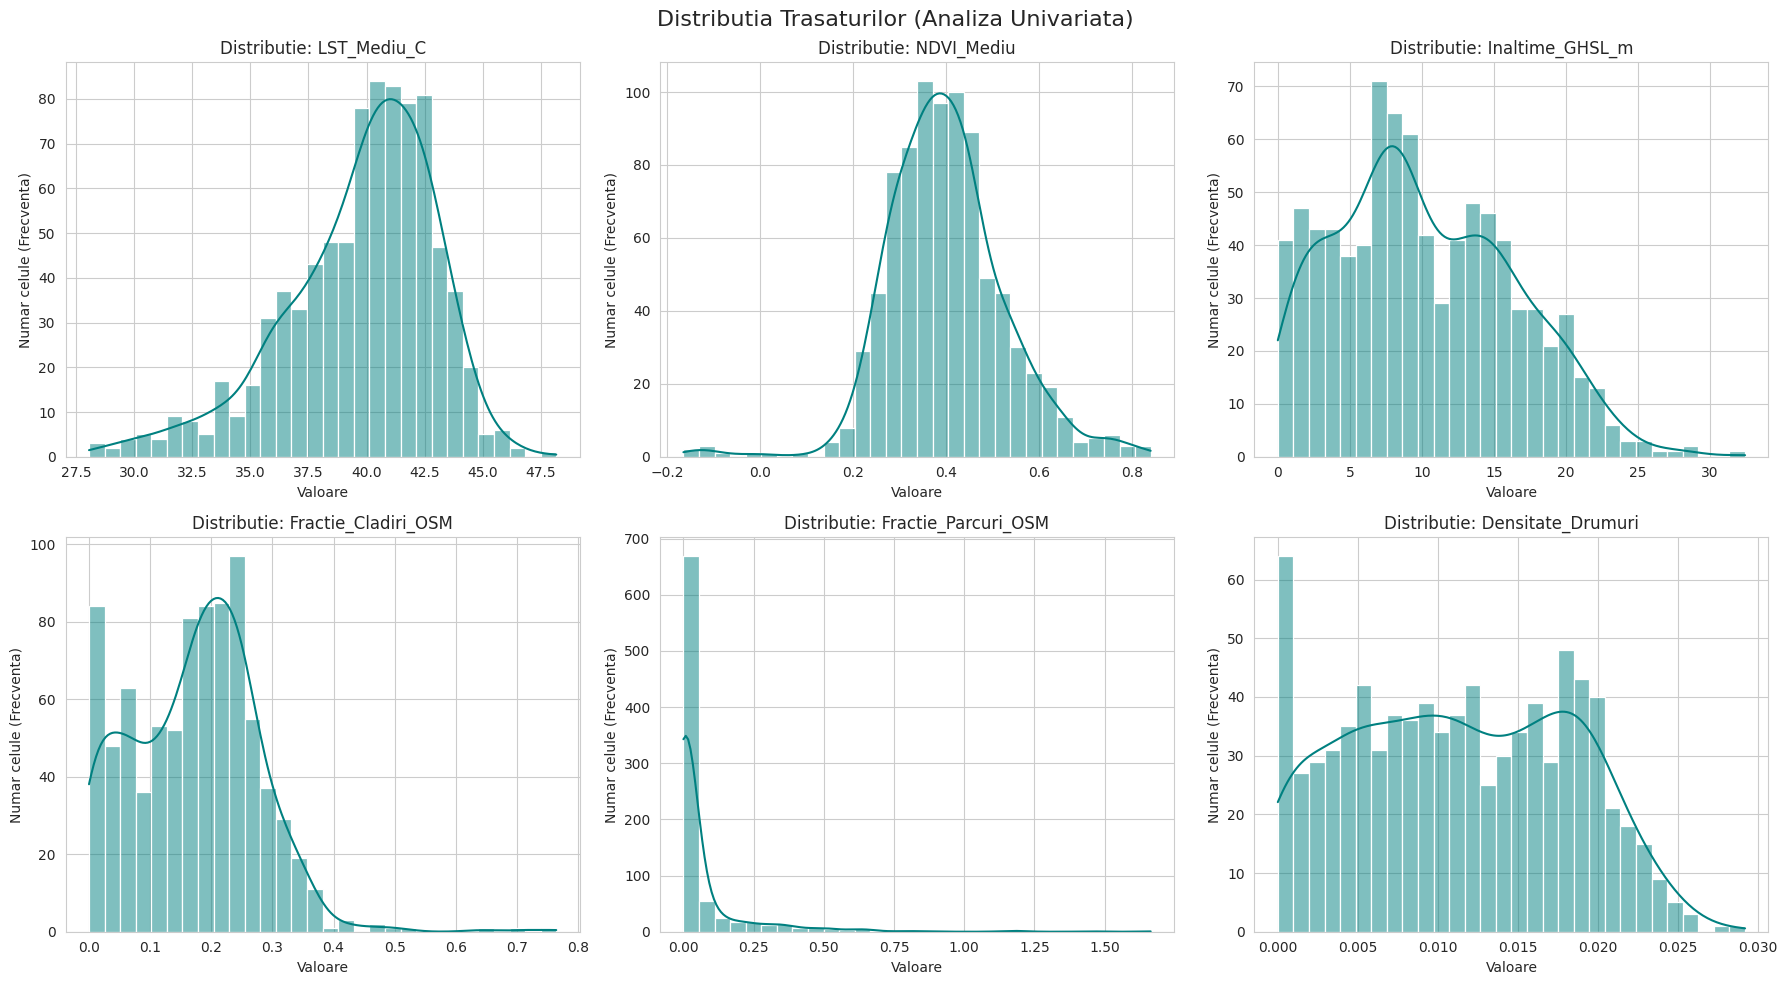

[LOG] 2.2 Generare matrice de corelatie (analiza bivariata)...


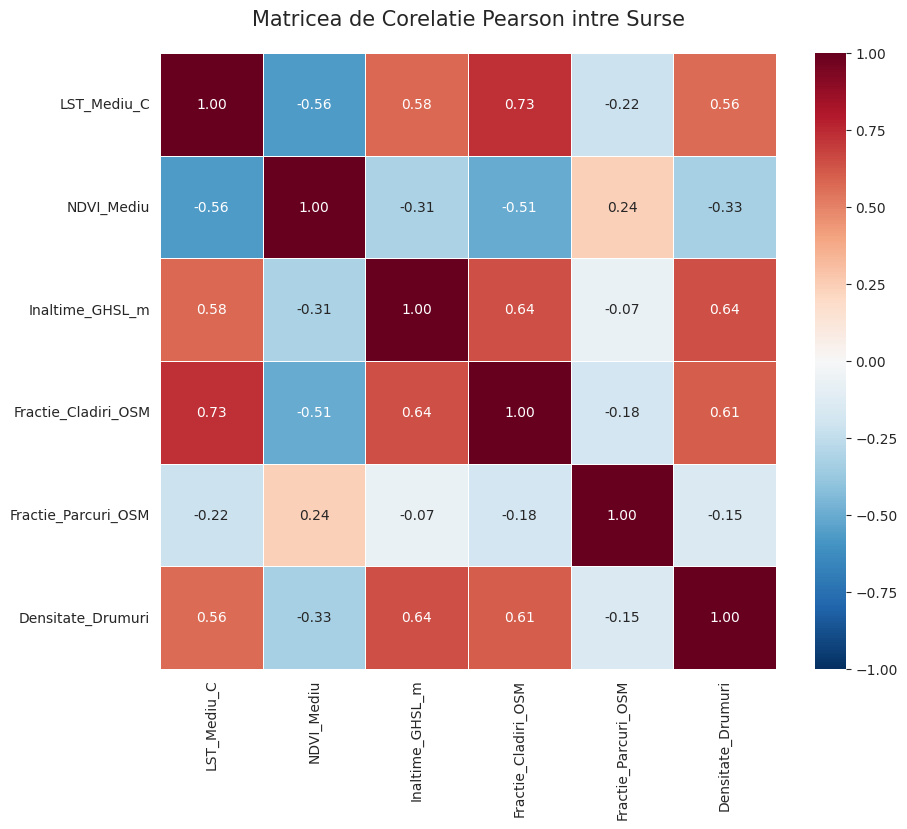

[LOG] Pasul 2 complet. Graficele au fost salvate pe disc.



In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# PASUL 2: ANALIZA STATISTICA DESCRIPTIVA
# ==========================================
print("[LOG] Incepe Pasul 2: Analiza statistica descriptiva...")

# Lista coloanelor de interes pentru analiza (fara coloane de geometrie sau ID)
coloane_analiza = [
    'LST_Mediu_C',
    'NDVI_Mediu',
    'Inaltime_GHSL_m',
    'Fractie_Cladiri_OSM',
    'Fractie_Parcuri_OSM',
    'Densitate_Drumuri'
]

# Pastram doar datele numerice pentru statistici
df_stat = matrice_X_gdf[coloane_analiza].copy()

# ------------------------------------------
# 2.1 Analiza univariata: Histograme
# ------------------------------------------
print("[LOG] 2.1 Generare histograme (analiza univariata)...")

# Setam stilul general al graficelor
sns.set_style("whitegrid")

# Cream o figura mare cu subgrafice (2 randuri, 3 coloane)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distributia Trasaturilor (Analiza Univariata)', fontsize=16)

# Parcurgem coloanele si generam histogramele automat
for i, col in enumerate(coloane_analiza):
    row = i // 3
    idx = i % 3
    # Histplot cu curba de densitate (kde=True)
    sns.histplot(df_stat[col], kde=True, ax=axes[row, idx], color='teal', bins=30)
    axes[row, idx].set_title(f'Distributie: {col}', fontsize=12)
    axes[row, idx].set_xlabel('Valoare')
    axes[row, idx].set_ylabel('Numar celule (Frecventa)')

plt.tight_layout()
# Salvam graficul ca imagine pentru a-l pune direct in Slide-ul 2
plt.savefig('distributii_univariate.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------
# 2.2 Analiza bivariata: Matricea de corelatie
# ------------------------------------------
print("[LOG] 2.2 Generare matrice de corelatie (analiza bivariata)...")

# Calculam matricea de corelatie liniara Pearson
matrice_corelatie = df_stat.corr()

# Setam dimensiunea figurii pentru Heatmap
plt.figure(figsize=(10, 8))

# Generam heatmap-ul folosind seaborn
sns.heatmap(
    matrice_corelatie,
    annot=True,         # Afiseaza valorile numerice in celule
    fmt=".2f",          # Formateaza la 2 zecimale
    cmap="RdBu_r",      # Paleta de culori: Rosu (corelatie pozitiva), Albastru (negativa)
    vmin=-1, vmax=1,    # Fortam scala sa fie intre -1 si 1
    linewidths=0.5,     # Linii despartitoare intre celule
    square=True         # Celulele vor fi patrate
)

plt.title('Matricea de Corelatie Pearson intre Surse', fontsize=15, pad=20)

# Salvam heatmap-ul ca imagine pentru Slide-ul 2
plt.savefig('heatmap_corelatii.png', dpi=300, bbox_inches='tight')
plt.show()

print("[LOG] Pasul 2 complet. Graficele au fost salvate pe disc.\n")

PASUL 3: Rularea baseline-ului PCA.

[LOG] Incepe Pasul 3: Reducerea dimensionalitatii (PCA Baseline)...
[LOG] Split realizat: 676 celule antrenare, 169 celule testare.
[LOG] Datele au fost scalate (StandardScaler).


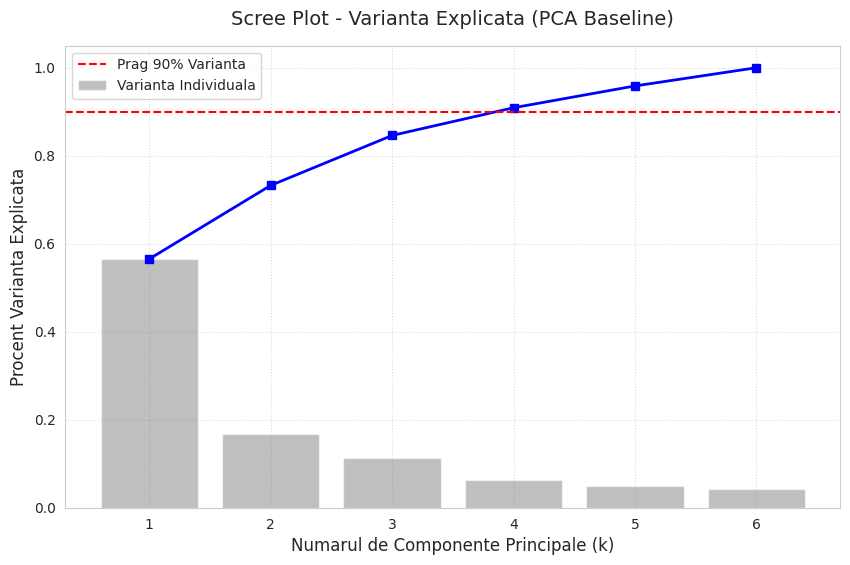


[LOG] Varianta cumulata per componenta:
  PC1: 56.51%
  PC2: 73.24%
  PC3: 84.60%
  PC4: 90.90%
  PC5: 95.86%
  PC6: 100.00%

[LOG] Loadings (Cum se formeaza PC1 si PC2):
                       PC1    PC2
LST_Mediu_C          0.473 -0.049
NDVI_Mediu          -0.396  0.252
Inaltime_GHSL_m      0.424  0.337
Fractie_Cladiri_OSM  0.482  0.079
Fractie_Parcuri_OSM -0.164  0.879
Densitate_Drumuri    0.424  0.204

[LOG] Metrica PCA Baseline:
  -> Eroarea de reconstructie (MSE) pe setul de test (cu k=3): 0.2518
[LOG] Pasul 3 complet.



In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# ==========================================
# PASUL 3: RULAREA BASELINE-ULUI PCA
# ==========================================
print("[LOG] Incepe Pasul 3: Reducerea dimensionalitatii (PCA Baseline)...")

# 3.1 Pregatirea datelor si Split-ul (Alegem un split aleator / spatial)
# Pastram doar coloanele cu trasaturi (fara geometrie sau ID)
coloane_trasaturi = [
    'LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m',
    'Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri'
]

X = matrice_X_gdf[coloane_trasaturi]

# Facem un split 80% antrenare (fit) si 20% testare
# Acest split simuleaza validarea pe o zona nevazuta pentru a masura metrica de reprezentare
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
print(f"[LOG] Split realizat: {len(X_train)} celule antrenare, {len(X_test)} celule testare.")

# 3.2 Scalarea datelor (Standardizare)
# Este obligatoriu sa fitam scalerul DOAR pe datele de antrenare pentru a evita leakage-ul
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("[LOG] Datele au fost scalate (StandardScaler).")

# 3.3 Aplicare PCA pe toate componentele pentru Scree Plot
pca_full = PCA()
pca_full.fit(X_train_scaled)

varianta_explicata = pca_full.explained_variance_ratio_
varianta_cumulata = varianta_explicata.cumsum()

# 3.4 Generare Scree Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(varianta_explicata) + 1), varianta_cumulata, marker='s', linestyle='-', color='b', linewidth=2)
plt.bar(range(1, len(varianta_explicata) + 1), varianta_explicata, alpha=0.5, color='gray', label='Varianta Individuala')

# Adaugam o linie rosie la pragul de 90% varianta explicata
plt.axhline(y=0.90, color='r', linestyle='--', label='Prag 90% Varianta')

plt.title('Scree Plot - Varianta Explicata (PCA Baseline)', fontsize=14, pad=15)
plt.xlabel('Numarul de Componente Principale (k)', fontsize=12)
plt.ylabel('Procent Varianta Explicata', fontsize=12)
plt.xticks(range(1, len(varianta_explicata) + 1))
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.savefig('scree_plot_pca.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n[LOG] Varianta cumulata per componenta:")
for i, var in enumerate(varianta_cumulata):
    print(f"  PC{i+1}: {var*100:.2f}%")

# 3.5 Extragere Loadings
# Ponderile fiecarei trasaturi initiale in constructia primelor componente
loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=[f'PC{i+1}' for i in range(len(coloane_trasaturi))],
    index=coloane_trasaturi
)

print("\n[LOG] Loadings (Cum se formeaza PC1 si PC2):")
print(loadings[['PC1', 'PC2']].round(3))

# 3.6 Calculare Metrici de Reprezentare (Eroare de Reconstructie pe split-ul de test)
# Presupunem ca alegem k=3 componente (care de obicei explica >85-90% din varianta)
k_ales = 3
pca_k = PCA(n_components=k_ales)
pca_k.fit(X_train_scaled)

# Proiectam datele de test in spatiul redus (k=3), apoi le reconstruim in spatiul original
X_test_proiectat = pca_k.transform(X_test_scaled)
X_test_reconstruit = pca_k.inverse_transform(X_test_proiectat)

# Calculam Mean Squared Error (MSE) intre datele originale scalate si cele reconstruite
eroare_reconstructie = mean_squared_error(X_test_scaled, X_test_reconstruit)

print(f"\n[LOG] Metrica PCA Baseline:")
print(f"  -> Eroarea de reconstructie (MSE) pe setul de test (cu k={k_ales}): {eroare_reconstructie:.4f}")
print("[LOG] Pasul 3 complet.\n")